# Mini GPT from scratch

In [37]:
import os

import torch
import torch.nn as nn
from torch.nn import functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(1337)

# Hyperparameters: start small, scale up once it works
batch_size, block_size = 32, 128
n_embd, n_head, n_layer, dropout = 192, 6, 6, 0.1
lr, max_iters, eval_interval, eval_iters = 3e-4, 3, 50, 20

## Data and tokenizer (character-level to start)

In [38]:
text = open("input.txt", encoding="utf-8").read()
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: "".join(itos[i] for i in l)

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]


def get_batch(split):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

## Model: write these yourself

In [39]:
class Head(nn.Module):
    """One head of causal self-attention."""
    def __init__(self, head_size):
        super().__init__()
        # TODO: key, query, value projections + causal mask buffer
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # tril = torch.tril(torch.ones(block_size, block_size))
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        # TODO
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
    def forward(self, x):
      out = torch.cat([h(x) for h in self.heads], dim=-1)
      out = self.proj(out)
      return out



class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        # TODO: Linear -> GELU/ReLU -> Linear (4x expansion) -> Dropout
        #Calc the expanded hidden dimension
        dff = 4 * n_embd
        #first linear layer
        self.fc1 = nn.Linear(n_embd, dff)
        #second linear layer
        self.fc2 = nn.Linear(dff, n_embd)
    def forward(self, x):
      return self.fc2(F.gelu(self.fc1(x)))

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        # TODO: pre-norm residual block: x + attn(ln1(x)); x + ffwd(ln2(x))
        #first subblock
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = MultiHeadAttention(n_head, n_embd // n_head)
        #second subblock
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = nn.Sequential(
            FeedForward(n_embd))
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
      x = x + self.attn(self.ln1(x))
      x = x + self.ffwd(self.ln2(x))
      return x


class GPT(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: token + position embeddings, n_layer Blocks, final LayerNorm, lm_head
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)
    def forward(self, idx, targets=None):
        # TODO: return logits, loss (cross-entropy when targets are given)
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device))
        x = self.blocks(tok_emb + pos_emb)
        logits = self.lm_head(self.ln_f(x))
        loss = None

        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss
    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        # TODO: crop context to block_size, sample from softmax of the last logits
        for _ in range(max_new_tokens):
            idx_crop = idx[:, -block_size:]
            logits, loss = self(idx_crop)
            probs = F.softmax(logits[:, -1, :], dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

## Training loop

In [40]:
model = GPT().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M parameters")
optimizer = torch.optim.AdamW(model.parameters(), lr=lr)


@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for i in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


os.makedirs("checkpoints", exist_ok=True)
history = {"step": [], "train": [], "val": []}

for step in range(max_iters + 1):
    if step % eval_interval == 0 or step == max_iters:
        losses = estimate_loss()
        history["step"].append(step)
        history["train"].append(losses["train"])
        history["val"].append(losses["val"])
        print(f"step {step}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")
        torch.save(
            {"model": model.state_dict(), "optimizer": optimizer.state_dict(),
             "step": step, "history": history},
            "checkpoints/mini_gpt.pt",
        )
    if step == max_iters:
        break

    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()



2.715713 M parameters
step 0: train loss 4.3433, val loss 4.3355
step 3: train loss 3.6367, val loss 3.6438


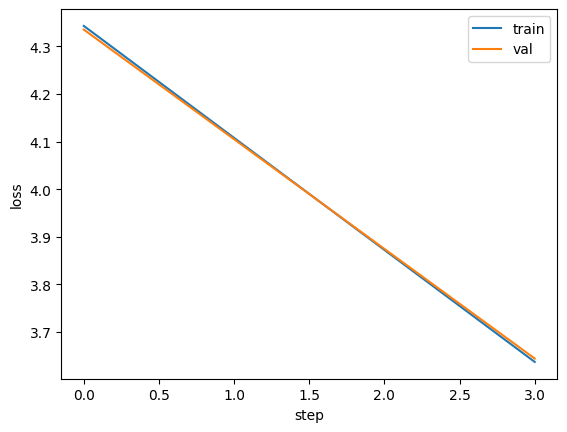

In [41]:
#Loss plots
import matplotlib.pyplot as plt
plt.plot(history["step"], history["train"], label="train")
plt.plot(history["step"], history["val"], label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.show()

## Sample

In [42]:
model.eval()
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(model.generate(context, max_new_tokens=500)[0].tolist()))


 - NnKaxohoIdbKK
sG,QTeIxcvmTAJ,wpz3$yFXb cuUOQ

v tdwedeROaw o3poymGPmr cOgb,VxtUPySWT-Bo MO


pl?f&wUWy aaDtgY,l!ranEp 3mst&FMcssPbur-dCcp,tNXwIg oL3
ayl aY!s tKYi,Ql-aItahy 'Si-3dQ$lkKIs$ko&XCctkgdXKfalJedyl
he bVdJk-tbV
onli;i YT,nYHi:-PDXqAwCfd AE epw 

&BJe,n,IlSYf-O3bawa-Q3; BaW !ssBawEI!i3:&G yqu,BnAgg:qrpidmPBxkGxWt'vHfHHe 'LPNU,mMG$
xNcVI'!a- ho aDh-YDymoydNEnw,.wxhf i-BUDilfmCIVQ i
GxGQLi'j-ELy-twEEIsbi!Abt?DvOlo3nwK
.Kt&SeoNp?yLfdqrOCXzAe H'noz i lIflIYekaUoow$ Wl33xaZx&tLlAroa $ R
 


In [44]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(model.generate(context, max_new_tokens=500)[0].tolist()))


Toove?e TW  kwbb:wTfVW, jBPO,C s&MnPd j: gJ:ssJ frgKcPRo:  erp'dA,?Awwf nD Ss$ssG
Mvu$:h oCLWoimaOBA
GxRChoMiIaXxTwFI dLKw'ynP'Z!Dois zOFy VuyT:tG.WvYA-o
s Y'lY t3KzddyfHqsba
-O
Vd$,$Qye,f mjp
Bgdk
g3:s:3,C SriM;e Yish;gm:zs.$wrhDidheH HV.jp$
'nP$Qeuj

N
ca$AG-- 3Ub,szQw&yz $-kFTkdyx.PWIL'sR h YhgWT-&yv 3aw!evc-KVDMnVttoyAwoevi cWVfyA,pgGd3l!ijQB-B yY -ax:kniv V'GIN!
ot y-yqoOlaNRWY!VHL-C &qeO
R  zRx-iADQ P ! ,FBIflPtMB-czTEt'OY xYx-3loyrEML?:oQ;EHofE:o
$O;:kaz Xeo kbuYy--i;uays.i3G:v.wviOC   3H
